In [6]:
import Level_1_project as l1p
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

results = l1p.optimize_parameters("G10_level_01_experiment_results.csv")
var_0, mu_0 = results[0][0], results[0][1]
print(f"Optimized parameters: mu_0 = {mu_0}, var_0 = {var_0}")

df_results = pd.read_csv("G10_level_01_experiment_results.csv")
df_results['y'] = 1 - df_results['Decision (S1>S2)']

Optimized parameters: mu_0 = 0.764729811579522, var_0 = 0.6986927478998974


In [10]:
def PSI(x_ref, x_test, var_ref, var_test, mu_0, var_0):
    return l1p.psi_i(var_0, mu_0, x_ref, var_ref, x_test, var_test)





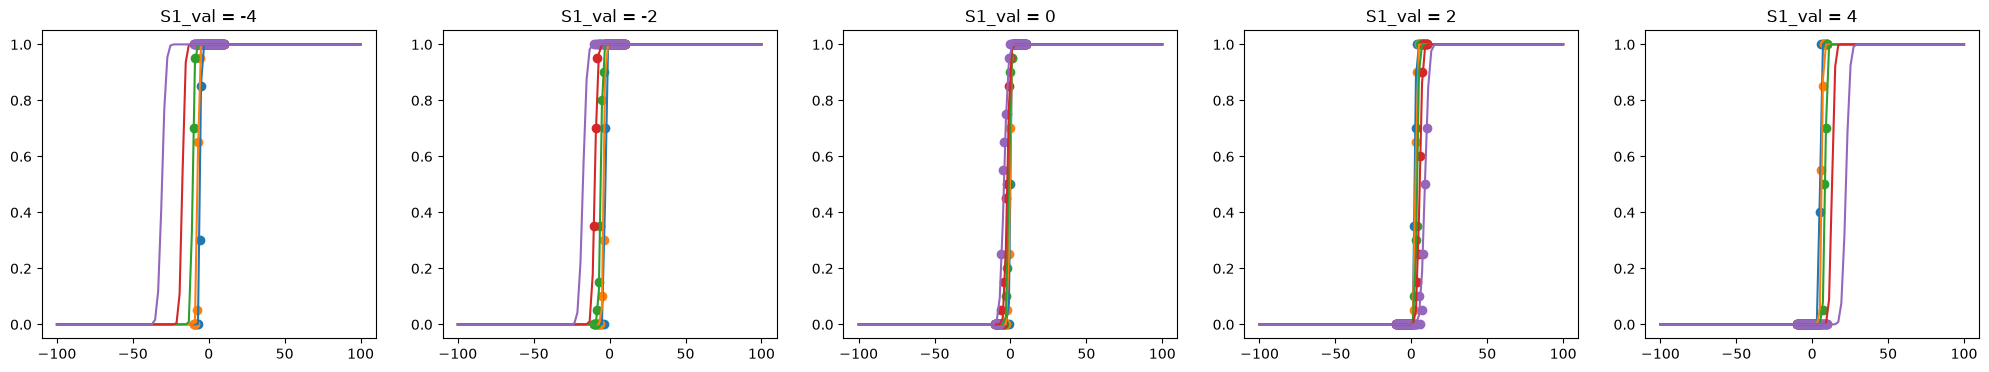

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(25, 4))
x_theo = np.linspace(-100, 100, 100)
for i, (x_ref, df_group) in enumerate(df_results.groupby('S1_val')):
    ax = axes[i]
    ax.set_title(f"S1_val = {x_ref}")
    for var_test, df_subgroup in df_group.groupby('S2_var'):
        mean_y = df_subgroup.groupby('S2_val')['y'].mean()
        ax.scatter(mean_y.index, mean_y.values, label=f'Var={var_test}')
        y_theorique = PSI(x_ref, x_theo, 0.01, var_test, mu_0, var_0)
        ax.plot(x_theo, y_theorique)

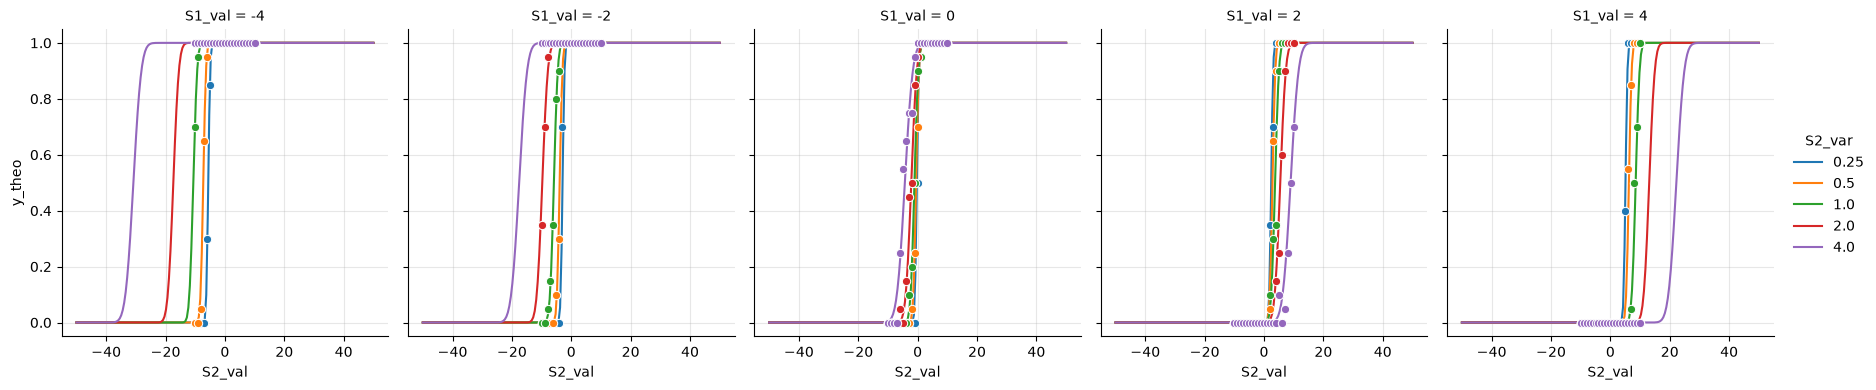

In [ ]:
x_lisse = np.linspace(-50, 50, 200)
lignes_theo = []
for x_ref in sorted(df_results['S1_val'].unique()):
  for var_test in sorted(df_results['S2_var'].unique()):
    y_th = PSI(x_ref, x_lisse, 0.01, var_test, mu_0, var_0)
    lignes_theo.append(
        pd.DataFrame({
            'S1_val': x_ref,
            'S2_val': x_lisse,
            'y_theo': y_th,
            'S2_var': var_test,
        })
    )
df_theo_all = pd.concat(lignes_theo, ignore_index=True)


palette = sns.color_palette('tab10', n_colors=df_results['S2_var'].nunique())
g = sns.relplot(
    data=df_theo_all,
    x='S2_val',
    y='y_theo',
    hue='S2_var',
    col='S1_val',
    kind='line',
    palette=palette,
    height=4,
    aspect=0.9,
)

for x_ref, ax in g.axes_dict.items():
  df_sub = df_results[df_results['S1_val'] == x_ref]
  sns.lineplot(
      data=df_sub,
      x='S2_val',
      y='y',
      hue='S2_var',
      palette=palette,
      marker='o',
      linestyle='',
      errorbar=None,
      legend=False,
      ax=ax,
  )
  ax.grid(True, alpha=0.3)

plt.show()